# Import library dan muat data

In [1]:
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn import metrics
from scipy.stats import shapiro
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

import statsmodels.api as sm
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan

warnings.filterwarnings("ignore")
print("Library berhasil di-import")

Library berhasil di-import


Dataset: **S&P 500 Companies with Financial Information** (Kaggle, `paytonfisher/sp-500-companies-with-financial-information`). Satu baris = satu perusahaan (data *cross-sectional*, bukan deret waktu).

In [2]:
path = "Data/financials.csv"
df = pd.read_csv(path)

print("Ukuran data (baris, kolom):", df.shape)
df.head()

Ukuran data (baris, kolom): (505, 14)


,Symbol,Name,Sector,Price,Price/Earnings,Dividend Yield,Earnings/Share,52 Week Low,52 Week High,Market Cap,EBITDA,Price/Sales,Price/Book,SEC Filings
0,MMM,3M Company,Industrials,222.89,24.31,2.332862,7.92,259.77,175.490,1.387211e+11,9.048000e+09,4.390271,11.34,http://www.sec.gov/cgi-bin/browse-edgar?action...
1,AOS,A.O. Smith Corp,Industrials,60.24,27.76,1.147959,1.70,68.39,48.925,1.078342e+10,6.010000e+08,3.575483,6.35,http://www.sec.gov/cgi-bin/browse-edgar?action...
2,ABT,Abbott Laboratories,Health Care,56.27,22.51,1.908982,0.26,64.60,42.280,1.021210e+11,5.744000e+09,3.740480,3.19,http://www.sec.gov/cgi-bin/browse-edgar?action...
3,ABBV,AbbVie Inc.,Health Care,108.48,19.41,2.499560,3.29,125.86,60.050,1.813863e+11,1.031000e+10,6.291571,26.14,http://www.sec.gov/cgi-bin/browse-edgar?action...
4,ACN,Accenture plc,Information Technology,150.51,25.47,1.714470,5.44,162.60,114.820,9.876586e+10,5.643228e+09,2.604117,10.62,http://www.sec.gov/cgi-bin/browse-edgar?action...


**Interpretasi:** Data kita berisi 505 perusahaan dengan 14 kolom. Empat kolom berisi identitas (`Symbol`, `Name`, `Sector`, `SEC Filings`), sedangkan 10 kolom lainnya berisi angka keuangan. Satu baris mewakili satu perusahaan, jadi data ini bersifat *cross-sectional* dan tidak punya urutan waktu.

---

# EDA dan preprocessing (info, deskriptif, missing, duplikat)

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 505 entries, 0 to 504
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Symbol          505 non-null    str    
 1   Name            505 non-null    str    
 2   Sector          505 non-null    str    
 3   Price           505 non-null    float64
 4   Price/Earnings  503 non-null    float64
 5   Dividend Yield  505 non-null    float64
 6   Earnings/Share  505 non-null    float64
 7   52 Week Low     505 non-null    float64
 8   52 Week High    505 non-null    float64
 9   Market Cap      505 non-null    float64
 10  EBITDA          505 non-null    float64
 11  Price/Sales     505 non-null    float64
 12  Price/Book      497 non-null    float64
 13  SEC Filings     505 non-null    str    
dtypes: float64(10), str(4)
memory usage: 55.4 KB


**Interpretasi:** Dari `info()` kelihatan ada 505 baris dan 14 kolom. Empat kolom bertipe teks (`str`) dan sepuluh kolom bertipe `float64`, jadi tipe datanya sudah sesuai dan tidak ada kolom angka yang terbaca sebagai teks. Ada dua kolom yang punya nilai kosong, yaitu `Price/Earnings` (503 terisi) dan `Price/Book` (497 terisi).

In [4]:
num_cols = df.select_dtypes(include="number").columns.tolist()
df[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
Price,505.0,1.038306e+02,1.344276e+02,2.820000e+00,4.625000e+01,7.392000e+01,1.165400e+02,1.806060e+03
Price/Earnings,503.0,2.480839e+01,4.124108e+01,-2.515300e+02,1.535000e+01,1.945000e+01,2.575000e+01,5.201500e+02
Dividend Yield,505.0,1.895953e+00,1.537214e+00,0.000000e+00,7.948336e-01,1.769255e+00,2.781114e+00,1.266120e+01
Earnings/Share,505.0,3.753743e+00,5.689036e+00,-2.801000e+01,1.490000e+00,2.890000e+00,5.140000e+00,4.409000e+01
52 Week Low,505.0,1.226238e+02,1.553621e+02,6.590000e+00,5.625000e+01,8.668000e+01,1.401300e+02,2.067990e+03
52 Week High,505.0,8.353662e+01,1.057255e+02,2.800000e+00,3.843000e+01,6.285000e+01,9.666000e+01,1.589000e+03
Market Cap,505.0,4.923944e+10,9.005017e+10,2.626102e+09,1.273207e+10,2.140095e+10,4.511968e+10,8.095080e+11
EBITDA,505.0,3.590328e+09,6.840544e+09,-5.067000e+09,7.739320e+08,1.614399e+09,3.692749e+09,7.938600e+10
Price/Sales,505.0,3.941705e+00,3.460110e+00,1.531862e-01,1.629490e+00,2.896440e+00,4.703842e+00,2.009429e+01
Price/Book,497.0,1.445318e+01,8.966051e+01,5.100000e-01,2.020000e+00,3.400000e+00,6.110000e+00,1.403380e+03


**Interpretasi:** Hampir semua variabel miring ke kanan. Contohnya `Price`: rata-ratanya sekitar 103,8 USD, tapi mediannya hanya sekitar 73,9 USD, dan nilai maksimumnya sampai sekitar 1.806 USD. `Earnings/Share` ada yang bernilai negatif (artinya perusahaan sedang rugi), `Dividend Yield` banyak yang bernilai 0 (perusahaan yang tidak membagikan dividen), dan `Price/Book` punya nilai maksimum sekitar 1.403 yang sangat jauh dari kuartil ketiganya. Hal-hal ini perlu kita perhatikan lagi di uji normalitas dan analisis outlier.

In [5]:
print("Missing value per kolom:")
print(df.isna().sum())

Missing value per kolom:
Symbol            0
Name              0
Sector            0
Price             0
Price/Earnings    2
Dividend Yield    0
Earnings/Share    0
52 Week Low       0
52 Week High      0
Market Cap        0
EBITDA            0
Price/Sales       0
Price/Book        8
SEC Filings       0
dtype: int64


**Interpretasi:** Nilai kosong cuma ada di `Price/Earnings` (2 baris) dan `Price/Book` (8 baris), kolom lainnya lengkap. Cara menanganinya kita tentukan setelah variabel model dipilih, karena belum tentu kedua kolom ini dipakai.

In [6]:
print("Baris duplikat penuh   :", df.duplicated().sum())
print("Simbol (Symbol) ganda  :", df["Symbol"].duplicated().sum())

Baris duplikat penuh   : 0
Simbol (Symbol) ganda  : 0


**Interpretasi:** Tidak ada baris duplikat, dan tidak ada simbol perusahaan yang muncul dua kali. Jadi di tahap ini tidak ada data yang perlu dibuang.

In [7]:
df.tail()

,Symbol,Name,Sector,Price,Price/Earnings,Dividend Yield,Earnings/Share,52 Week Low,52 Week High,Market Cap,EBITDA,Price/Sales,Price/Book,SEC Filings
500,XYL,Xylem Inc.,Industrials,70.24,30.94,1.170079,1.83,76.81,46.86,1.291502e+10,7.220000e+08,2.726209,5.31,http://www.sec.gov/cgi-bin/browse-edgar?action...
501,YUM,Yum! Brands Inc,Consumer Discretionary,76.30,27.25,1.797080,4.07,86.93,62.85,2.700330e+10,2.289000e+09,6.313636,212.08,http://www.sec.gov/cgi-bin/browse-edgar?action...
502,ZBH,Zimmer Biomet Holdings,Health Care,115.53,14.32,0.794834,9.01,133.49,108.17,2.445470e+10,2.007400e+09,3.164895,2.39,http://www.sec.gov/cgi-bin/browse-edgar?action...
503,ZION,Zions Bancorp,Financials,50.71,17.73,1.480933,2.60,55.61,38.43,1.067068e+10,0.000000e+00,3.794579,1.42,http://www.sec.gov/cgi-bin/browse-edgar?action...
504,ZTS,Zoetis,Health Care,71.51,32.80,0.682372,1.65,80.13,52.00,3.599111e+10,1.734000e+09,9.280896,18.09,http://www.sec.gov/cgi-bin/browse-edgar?action...


**Interpretasi:** Lima baris terakhir adalah perusahaan dengan simbol berawalan X sampai Z (XYL, YUM, ZBH, ZION, ZTS). Artinya data diurutkan berdasarkan simbol perusahaan, bukan berdasarkan waktu, sehingga urutan baris tidak punya makna waktu. Ini penting untuk membaca uji autokorelasi nanti.

---

# Kualitas data dan pembentukan variabel

In [8]:
# Cek logika: 52 Week Low seharusnya <= 52 Week High
salah = (df["52 Week Low"] > df["52 Week High"]).sum()
print("Baris dengan 52 Week Low > 52 Week High:", salah, "dari", len(df))

Baris dengan 52 Week Low > 52 Week High: 505 dari 505


**Interpretasi:** Di semua 505 baris, nilai `52 Week Low` justru lebih besar daripada `52 Week High`. Secara logika ini tidak mungkin, jadi bisa disimpulkan isi kedua kolom tertukar di file sumbernya. Kolom ini memang tidak dipakai sebagai fitur, tapi tetap kita perbaiki supaya datanya konsisten.

In [9]:
# Perbaiki: tukar nama kedua kolom, lalu cek ulang
df = df.rename(columns={"52 Week Low": "52 Week High",
                        "52 Week High": "52 Week Low"})

print("Setelah perbaikan, baris dengan Low > High:",
      (df["52 Week Low"] > df["52 Week High"]).sum())

Setelah perbaikan, baris dengan Low > High: 0


**Interpretasi:** Setelah nama kolom ditukar, sudah tidak ada lagi baris dengan `52 Week Low` > `52 Week High`. Perbaikan ini tidak memengaruhi model, karena kedua kolom tersebut tidak masuk sebagai fitur.

In [10]:
# Pemilihan variabel: bandingkan kandidat fitur terhadap Price
kandidat = ["Price/Earnings", "Dividend Yield", "Earnings/Share",
            "Market Cap", "EBITDA", "Price/Sales", "Price/Book"]

ringkas = pd.DataFrame({
    "missing"   : df[kandidat].isna().sum(),
    "korelasi_Price": df[kandidat].corrwith(df["Price"]).round(3),
    "skewness"  : df[kandidat].skew().round(2),
    "maks"      : df[kandidat].max(),
})
ringkas

,missing,korelasi_Price,skewness,maks
Price/Earnings,2,0.195,5.23,5.201500e+02
Dividend Yield,0,-0.245,1.30,1.266120e+01
Earnings/Share,0,0.591,1.89,4.409000e+01
Market Cap,0,0.406,5.24,8.095080e+11
EBITDA,0,0.180,5.42,7.938600e+10
Price/Sales,0,0.182,1.90,2.009429e+01
Price/Book,8,0.024,13.90,1.403380e+03


**Interpretasi:** Awalnya kita berencana memakai `Price/Book`, tapi variabel ini punya 8 nilai kosong, korelasinya dengan `Price` hampir nol (sekitar 0,02), skewness-nya sangat tinggi (sekitar 13,9), dan ada satu nilai ekstrem (sekitar 1.403). Sebaliknya, `Earnings/Share` punya korelasi paling kuat dengan `Price` (sekitar 0,59), disusul `Dividend Yield` (sekitar −0,25) dan `Price/Sales` (sekitar 0,18, tanpa nilai kosong). Jadi `Price/Book` kita ganti dengan `Price/Sales`.

Kolom lain sengaja tidak dipakai: `52 Week High/Low` nilainya hampir sama dengan `Price` itu sendiri, sedangkan `Market Cap` dan `EBITDA` sangat miring dan saling berkorelasi tinggi (sekitar 0,77).

In [11]:
TARGET   = "Price"
FEATURES = ["Earnings/Share", "Dividend Yield", "Price/Sales"]

data = df[[TARGET] + FEATURES].copy()

print("Ukuran data model:", data.shape)
print("Missing value    :", int(data.isna().sum().sum()))
data.head()

Ukuran data model: (505, 4)
Missing value    : 0


,Price,Earnings/Share,Dividend Yield,Price/Sales
0,222.89,7.92,2.332862,4.390271
1,60.24,1.70,1.147959,3.575483
2,56.27,0.26,1.908982,3.740480
3,108.48,3.29,2.499560,6.291571
4,150.51,5.44,1.714470,2.604117


**Interpretasi:** Data untuk model berisi 505 baris dengan 1 target (`Price`, harga saham dalam USD) dan 3 fitur numerik (`Earnings/Share`, `Dividend Yield`, `Price/Sales`). Ketiga fitur ini tidak punya nilai kosong, jadi tidak ada baris yang perlu dibuang atau diisi.

In [12]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
Price,505.0,103.830634,134.427636,2.820000,46.250000,73.920000,116.540000,1806.060000
Earnings/Share,505.0,3.753743,5.689036,-28.010000,1.490000,2.890000,5.140000,44.090000
Dividend Yield,505.0,1.895953,1.537214,0.000000,0.794834,1.769255,2.781114,12.661196
Price/Sales,505.0,3.941705,3.460110,0.153186,1.629490,2.896440,4.703842,20.094294


**Interpretasi:** Rata-rata `Price` sekitar 103,8 USD dengan median sekitar 73,9 USD, sedangkan nilai maksimumnya sekitar 1.806 USD (Priceline, simbol PCLN). Jadi sebarannya sangat miring ke kanan. `Earnings/Share` berkisar dari sekitar −28 sampai 44 USD (51 perusahaan bernilai negatif), `Dividend Yield` dari 0 sampai sekitar 12,7% (86 perusahaan bernilai 0), dan `Price/Sales` dari sekitar 0,15 sampai 20,1. Outlier pada `Price` akan kita bahas lagi di uji normalitas dan eksperimen outlier.

---

# Uji asumsi awal: normalitas, linearitas, multikolinearitas

## Uji normalitas

Sebaran tiap variabel kita lihat lewat histogram, boxplot, dan Q-Q plot, lalu kita buktikan dengan uji Shapiro-Wilk.

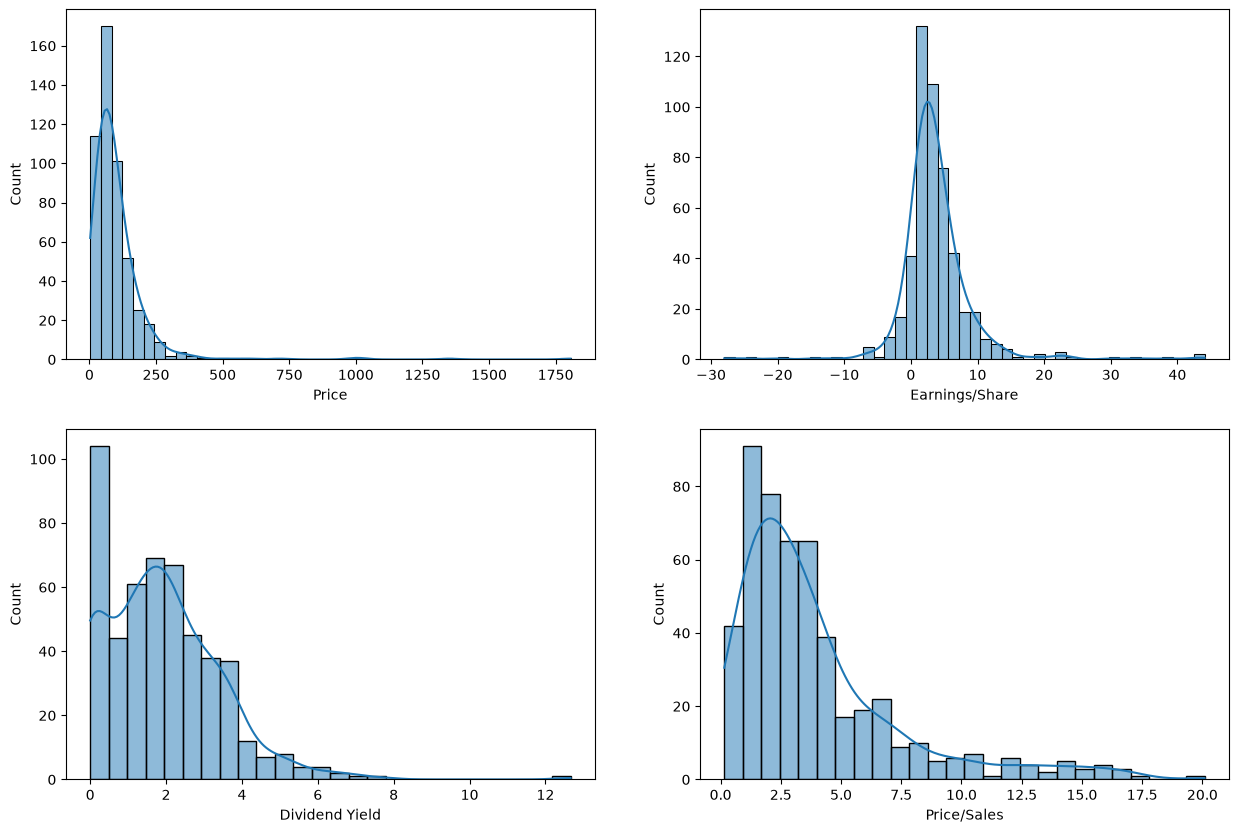

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

sns.histplot(data["Price"], kde=True, ax=axes[0, 0])
sns.histplot(data["Earnings/Share"], kde=True, ax=axes[0, 1])
sns.histplot(data["Dividend Yield"], kde=True, ax=axes[1, 0])
sns.histplot(data["Price/Sales"], kde=True, ax=axes[1, 1])
plt.show()

**Interpretasi:**
- **Price:** puncaknya ada di harga-harga kecil, lalu ekornya sangat panjang ke kanan sampai sekitar 1.800 USD. Bentuknya jauh dari lonceng.
- **Earnings/Share:** puncaknya sempit dan runcing di sekitar 2–3 USD, dengan ekor panjang ke dua arah (negatif sampai sekitar −28, positif sampai sekitar 44).
- **Dividend Yield:** ada tumpukan di angka 0 (perusahaan yang tidak membagi dividen), sisanya mirip lonceng yang condong ke kanan.
- **Price/Sales:** condong ke kanan, kebanyakan berada di kisaran 1–5 dengan ekor sampai sekitar 20.

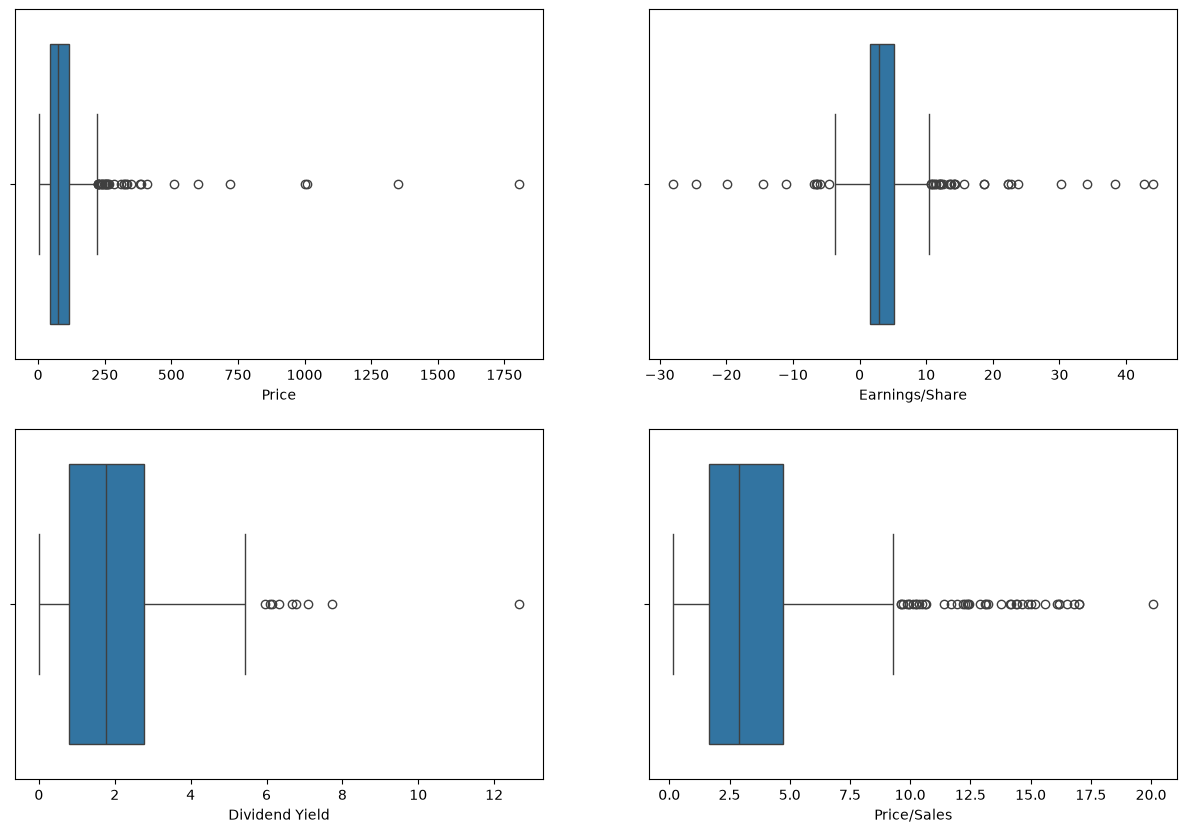

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

sns.boxplot(x=data["Price"], ax=axes[0, 0])
sns.boxplot(x=data["Earnings/Share"], ax=axes[0, 1])
sns.boxplot(x=data["Dividend Yield"], ax=axes[1, 0])
sns.boxplot(x=data["Price/Sales"], ax=axes[1, 1])
plt.show()

**Interpretasi:** Keempat variabel punya banyak titik outlier. Kalau dihitung pakai aturan 1,5 × IQR, jumlahnya sekitar 33 di `Price`, 41 di `Earnings/Share`, 9 di `Dividend Yield`, dan 43 di `Price/Sales`. `Price` paling ekstrem: ada empat saham di atas 1.000 USD (PCLN, AMZN, GOOGL, GOOG). `Earnings/Share` punya outlier di dua sisi, sedangkan variabel lain outlier-nya hanya di sisi kanan. Ini sejalan dengan histogram yang condong ke kanan.

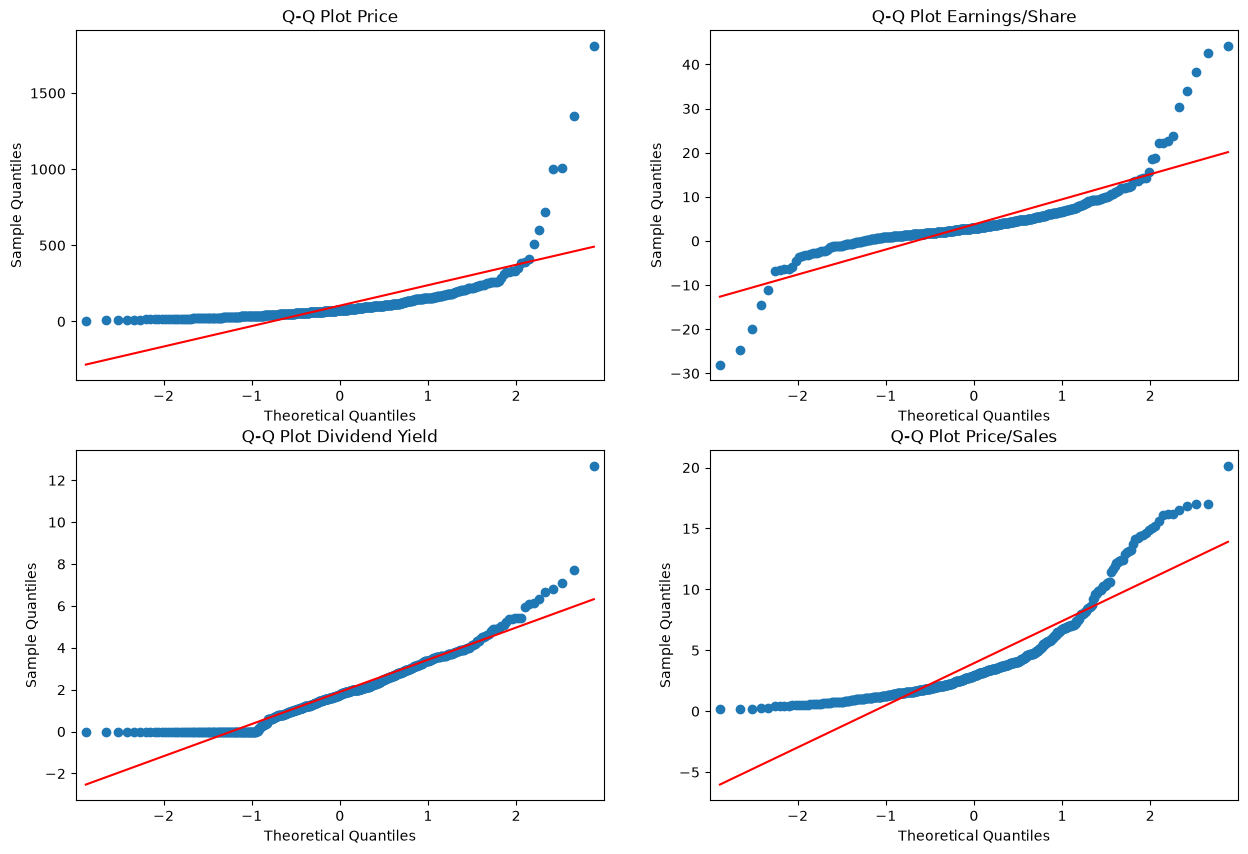

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

sm.graphics.qqplot(data["Price"], line='s', ax=axes[0, 0])
axes[0, 0].title.set_text('Q-Q Plot Price')

sm.graphics.qqplot(data["Earnings/Share"], line='s', ax=axes[0, 1])
axes[0, 1].title.set_text('Q-Q Plot Earnings/Share')

sm.graphics.qqplot(data["Dividend Yield"], line='s', ax=axes[1, 0])
axes[1, 0].title.set_text('Q-Q Plot Dividend Yield')

sm.graphics.qqplot(data["Price/Sales"], line='s', ax=axes[1, 1])
axes[1, 1].title.set_text('Q-Q Plot Price/Sales')

plt.show()

**Interpretasi:** Di keempat variabel, titik-titiknya melenceng dari garis merah, terutama di bagian ujung. `Price` melengkung tajam ke atas di ujung kanan karena outlier harga tinggi. `Earnings/Share` menyimpang di kedua ujung (ekornya berat). `Dividend Yield` mendatar di bagian kiri karena banyaknya nilai 0. `Price/Sales` membentuk lengkungan yang khas untuk data condong kanan. Jadi secara visual, tidak ada variabel yang berdistribusi normal.

In [16]:
column = data.columns

for i in column:
    stat, p = shapiro(data[i])
    print('Statistics=%.3f, p=%.3f' % (stat, p))
    alpha = 0.05
    if p > alpha:
        print('Gagal Tolak H0, {} berdistribusi normal'.format(i))
    else:
        print('Tolak H0, {} tidak berdistribusi normal'.format(i))

Statistics=0.456, p=0.000
Tolak H0, Price tidak berdistribusi normal
Statistics=0.732, p=0.000
Tolak H0, Earnings/Share tidak berdistribusi normal
Statistics=0.911, p=0.000
Tolak H0, Dividend Yield tidak berdistribusi normal
Statistics=0.797, p=0.000
Tolak H0, Price/Sales tidak berdistribusi normal


**Interpretasi:** Hipotesisnya H0: data berdistribusi normal dan H1: data tidak berdistribusi normal, dengan α = 0,05. Keempat variabel punya p < 0,05 (statistik W: `Price` 0,456; `Earnings/Share` 0,732; `Dividend Yield` 0,911; `Price/Sales` 0,797), jadi H0 ditolak dan tidak ada variabel yang berdistribusi normal. Hasil ini sejalan dengan histogram dan Q-Q plot. `Price` punya W paling kecil, jadi variabel inilah yang paling jauh dari normal.

**Keputusan:** asumsi normalitas variabel tidak terpenuhi. Catatan: di OLS, asumsi normalitas sebenarnya berlaku untuk residual, bukan untuk variabel X atau Y. Residual akan kita uji di Tahap 5.

## Uji linearitas

Linearitas artinya perubahan X diikuti perubahan Y dengan pola garis lurus. Garis merah (LOWESS) menunjukkan bentuk hubungan yang sebenarnya tanpa dipaksa lurus.

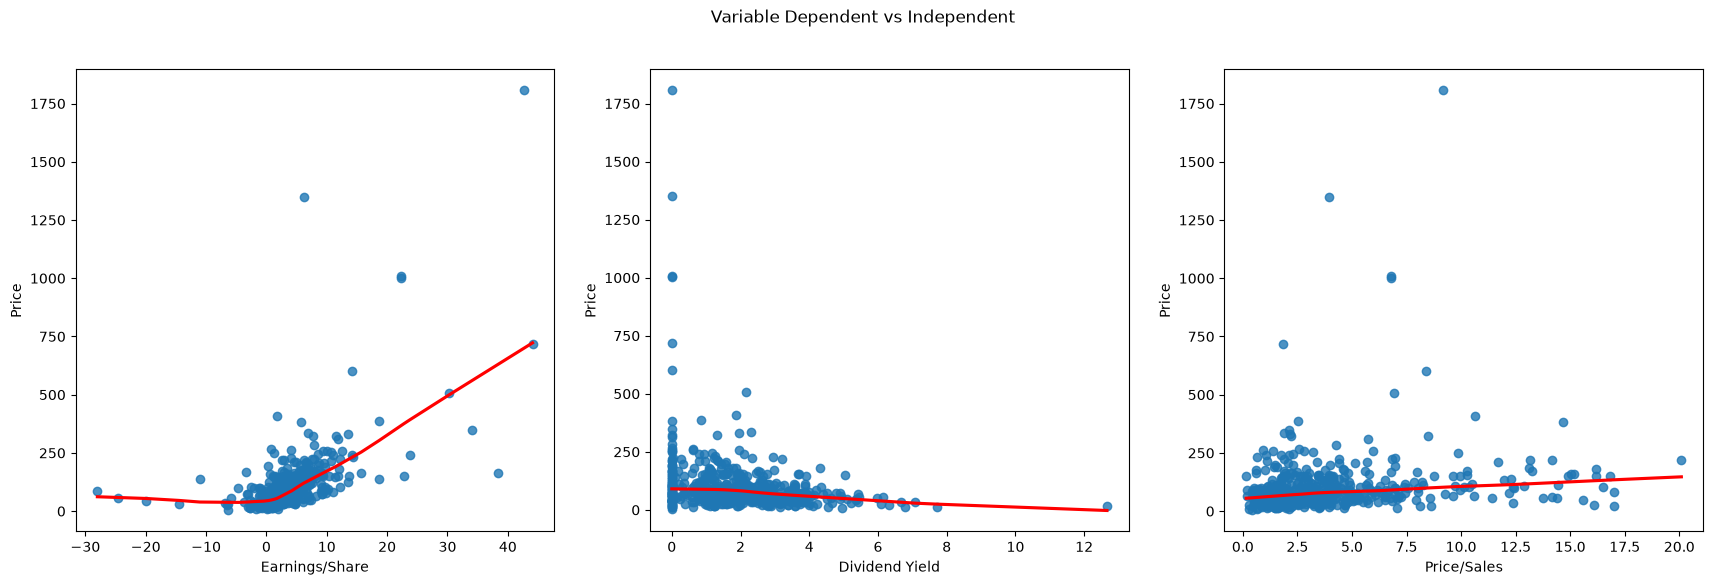

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(21, 6))
fig.suptitle('Variable Dependent vs Independent')

sns.regplot(x=data["Earnings/Share"], y=data["Price"], lowess=True, line_kws={'color': 'red'}, ax=axes[0])
sns.regplot(x=data["Dividend Yield"], y=data["Price"], lowess=True, line_kws={'color': 'red'}, ax=axes[1])
sns.regplot(x=data["Price/Sales"], y=data["Price"], lowess=True, line_kws={'color': 'red'}, ax=axes[2])
plt.show()

**Interpretasi:**
- **Earnings/Share:** hubungan positifnya paling jelas, tapi hanya untuk EPS positif. Di bagian itu garis naik cukup tajam. Untuk EPS negatif garisnya justru datar atau sedikit turun, jadi bentuknya mirip huruf "V" yang miring. Artinya perusahaan yang sedang rugi tidak otomatis harga sahamnya rendah.
- **Dividend Yield:** hubungannya negatif lemah dan garisnya cukup lurus. Makin tinggi dividend yield, harga saham cenderung lebih rendah. Ini masuk akal karena dividend yield dihitung dari dividen dibagi harga. Banyak titik menumpuk di angka 0.
- **Price/Sales:** hubungannya positif lemah, garisnya naik landai, dan titik-titiknya menyebar cukup luas.

Di ketiga grafik, beberapa saham dengan harga di atas 1.000 USD terlihat jauh di atas titik lainnya dan bisa ikut menarik garis.

**Keputusan:** linearitas terpenuhi sebagian. Paling baik di `Dividend Yield` dan `Price/Sales` (walaupun lemah), sedangkan `Earnings/Share` hanya linear di bagian positifnya.

## Uji multikolinearitas

Multikolinearitas adalah korelasi tinggi antar-variabel bebas, yang bikin estimasi koefisien jadi tidak stabil.

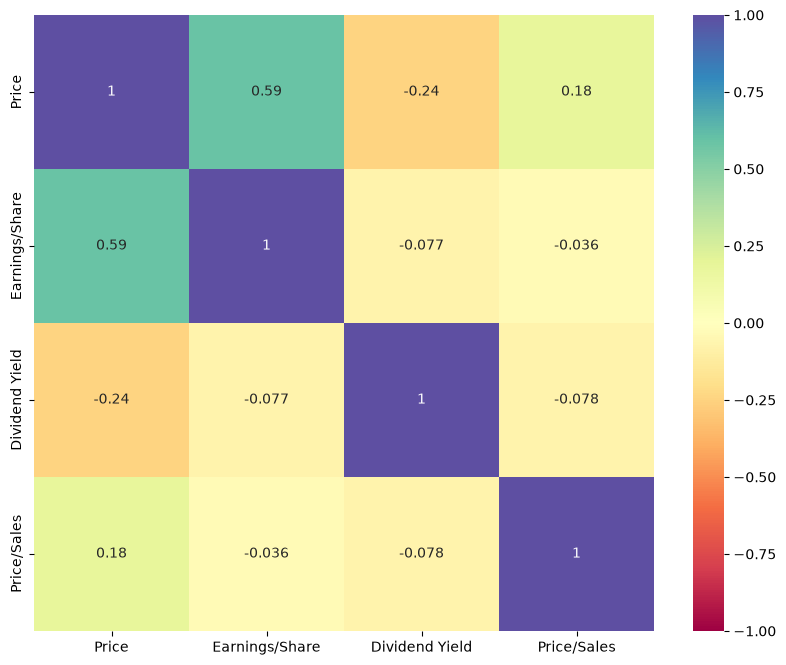

In [18]:
plt.figure(figsize=(10, 8))
sns.heatmap(data.corr(), vmax=1, vmin=-1, center=0, cmap="Spectral", annot=True)
plt.show()

**Interpretasi:** Korelasi antar-variabel bebas semuanya sangat kecil: `Earnings/Share`–`Dividend Yield` = −0,08; `Earnings/Share`–`Price/Sales` = −0,04; `Dividend Yield`–`Price/Sales` = −0,08. Nilai mutlaknya di bawah 0,1, jadi ketiga fitur ini hampir tidak saling berhubungan dan tidak ada tanda multikolinearitas.

In [19]:
korelasi = data.corr()[TARGET].sort_values()
korelasi

Dividend Yield   -0.244630
Price/Sales       0.181625
Earnings/Share    0.591061
Price             1.000000
Name: Price, dtype: float64

**Interpretasi:** `Earnings/Share` berkorelasi positif paling kuat dengan `Price` (0,59), `Price/Sales` positif lemah (0,18), dan `Dividend Yield` negatif lemah (−0,24). Dari sini sudah kelihatan kalau `Earnings/Share` kemungkinan besar jadi prediktor yang paling berpengaruh.

In [20]:
X_vif = sm.add_constant(data[FEATURES])

vif = pd.DataFrame({
    "variabel": FEATURES,
    "VIF": [variance_inflation_factor(X_vif.values, i) for i in range(1, X_vif.shape[1])],
})
vif

,variabel,VIF
0,Earnings/Share,1.007816
1,Dividend Yield,1.012614
2,Price/Sales,1.007893


**Interpretasi:** Nilai VIF ketiga fitur sekitar 1,01 (`Earnings/Share` 1,008; `Dividend Yield` 1,013; `Price/Sales` 1,008). Nilai ini jauh di bawah batas yang biasa dipakai (5 atau 10). VIF ≈ 1 artinya hampir tidak ada bagian dari satu fitur yang bisa dijelaskan oleh fitur lain.

**Keputusan:** asumsi bebas multikolinearitas terpenuhi.

**Ringkasan Tahap 3 dan keputusan:** normalitas variabel tidak terpenuhi, linearitas terpenuhi sebagian, dan multikolinearitas terpenuhi. Data tetap kita pakai apa adanya (tanpa transformasi dan tanpa membuang outlier di awal) supaya alurnya sama dengan modul. Dampak outlier akan kita cek di eksperimen outlier (Tahap 6), dan transformasi logaritma kita masukkan sebagai saran perbaikan.

---

# Split, scaling, dan model OLS

Berbeda dengan modul (scaling dulu baru split), di sini data kita **split dulu**, lalu `StandardScaler` hanya di-*fit* pada data latih. Data uji cukup di-*transform* pakai rata-rata dan simpangan baku dari data latih, supaya informasi data uji tidak "bocor" ke model (*data leakage*).

In [21]:
X = data[FEATURES]
y = data[TARGET]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)

In [22]:
print("Ukuran X train ", len(X_train))
print("Ukuran X test  ", len(X_test))
print("Ukuran y train ", len(y_train))
print("Ukuran y test  ", len(y_test))

Ukuran X train  353
Ukuran X test   152
Ukuran y train  353
Ukuran y test   152


**Interpretasi:** Data latih berisi 353 perusahaan dan data uji 152 perusahaan (353 + 152 = 505). Proporsinya sekitar 70% : 30%, sesuai `test_size=0.3`. Karena `random_state=0`, pembagiannya akan selalu sama setiap kali dijalankan.

In [23]:
scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_train_scaled = pd.DataFrame(scaler_X.fit_transform(X_train), columns=FEATURES, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler_X.transform(X_test), columns=FEATURES, index=X_test.index)

y_train_scaled = pd.Series(scaler_y.fit_transform(y_train.to_frame()).ravel(), index=y_train.index, name=TARGET)
y_test_scaled = pd.Series(scaler_y.transform(y_test.to_frame()).ravel(), index=y_test.index, name=TARGET)

print("Rata-rata Price (data latih):", scaler_y.mean_[0])
print("SD Price (data latih)       :", scaler_y.scale_[0])
X_train_scaled.describe().round(3)

Rata-rata Price (data latih): 100.63946175637393
SD Price (data latih)       : 121.97514738501847


,Earnings/Share,Dividend Yield,Price/Sales
count,353.000,353.000,353.000
mean,-0.000,0.000,0.000
std,1.001,1.001,1.001
min,-5.448,-1.224,-1.101
25%,-0.384,-0.716,-0.657
50%,-0.157,-0.089,-0.291
75%,0.221,0.597,0.259
max,6.901,6.676,4.983


**Interpretasi:** Setelah scaling, ketiga fitur di data latih punya rata-rata 0 dan simpangan baku sekitar 1 (tertulis 1,001 karena `describe()` memakai pembagi n − 1). Scaler untuk `Price` belajar dari data latih saja: rata-ratanya sekitar 100,64 USD dan simpangan bakunya sekitar 121,98 USD. Dua angka ini nanti kita pakai untuk mengubah galat kembali ke satuan USD. Data uji hanya di-*transform*, jadi rata-ratanya tidak persis 0 dan itu memang wajar.

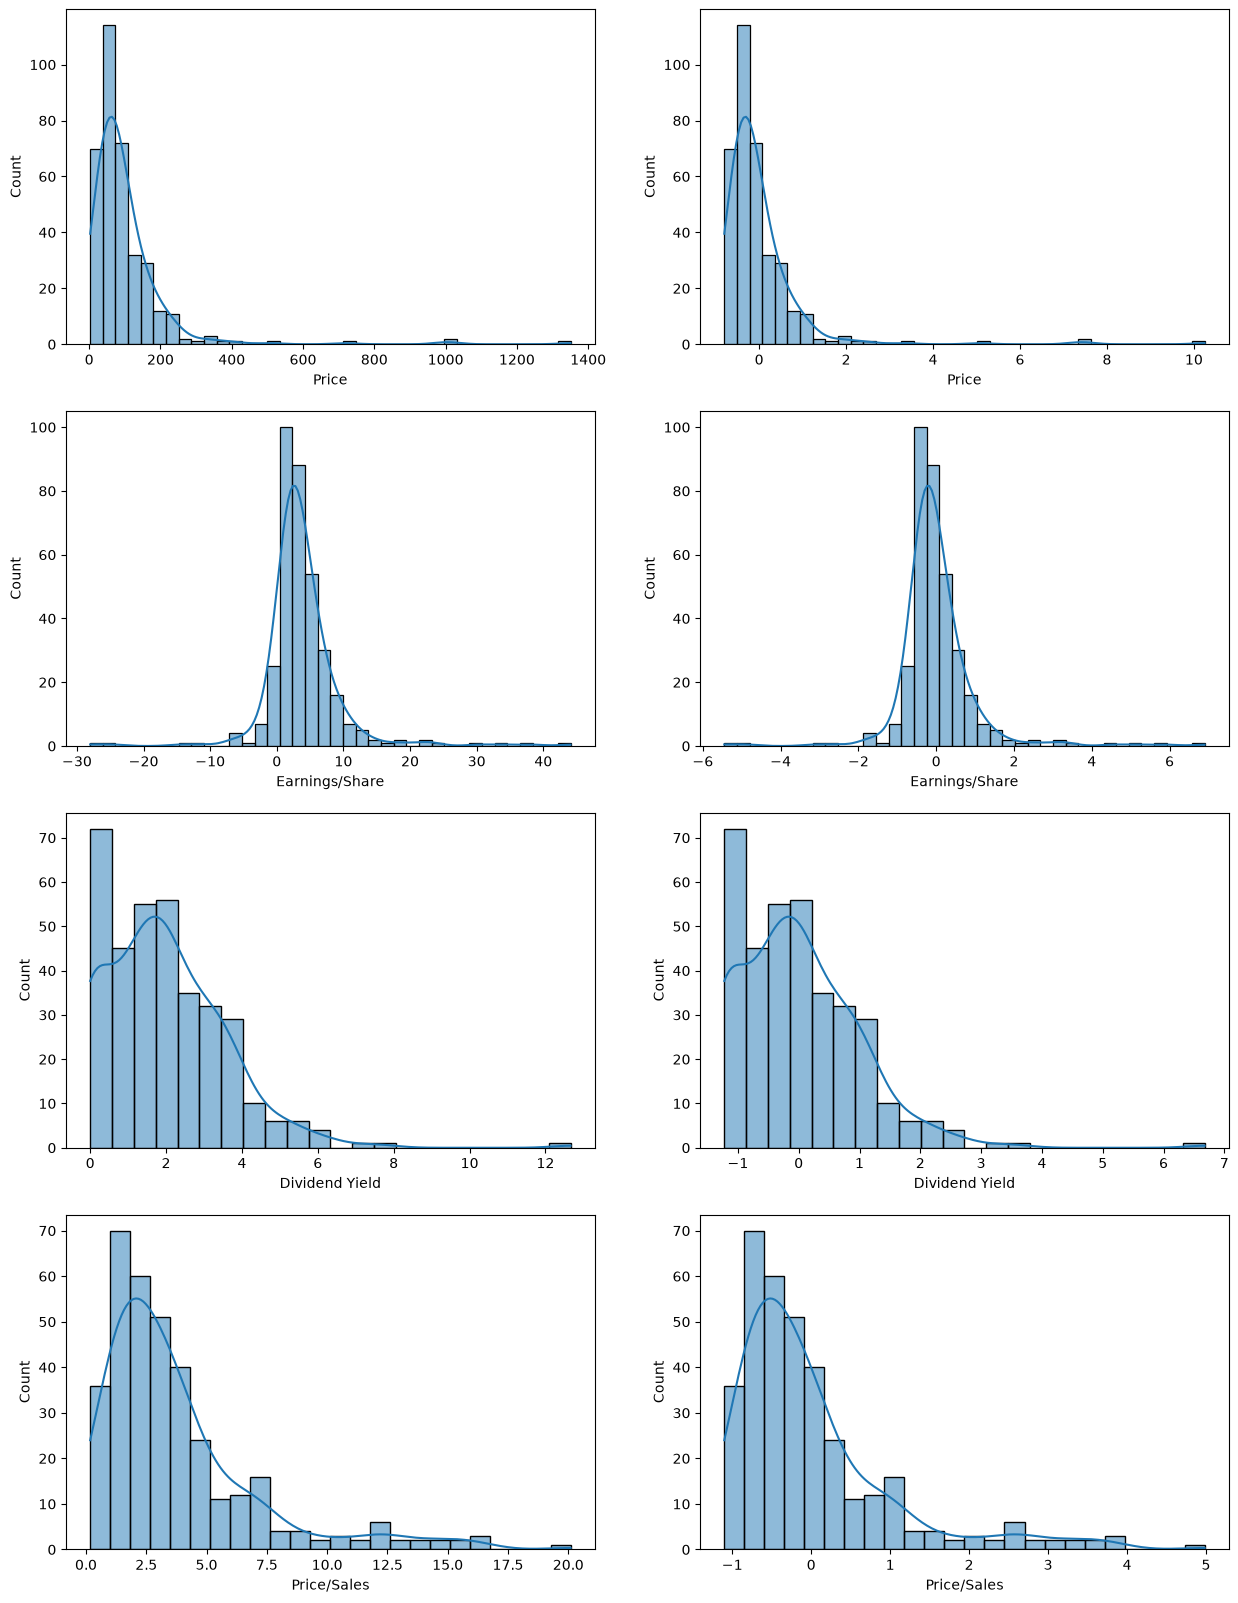

In [24]:
fig, axes = plt.subplots(4, 2, figsize=(15, 20))

sns.histplot(y_train, kde=True, ax=axes[0, 0])
sns.histplot(y_train_scaled, kde=True, ax=axes[0, 1])
sns.histplot(X_train["Earnings/Share"], kde=True, ax=axes[1, 0])
sns.histplot(X_train_scaled["Earnings/Share"], kde=True, ax=axes[1, 1])
sns.histplot(X_train["Dividend Yield"], kde=True, ax=axes[2, 0])
sns.histplot(X_train_scaled["Dividend Yield"], kde=True, ax=axes[2, 1])
sns.histplot(X_train["Price/Sales"], kde=True, ax=axes[3, 0])
sns.histplot(X_train_scaled["Price/Sales"], kde=True, ax=axes[3, 1])
plt.show()

**Interpretasi:** Kolom kiri adalah data latih asli dan kolom kanan hasil scaling. Bentuk histogramnya sama persis, yang berubah hanya angka di sumbu horizontal: rata-ratanya jadi 0 dan satuannya jadi simpangan baku. Ini membuktikan bahwa scaling hanya mengubah skala, bukan bentuk distribusi. Jadi kemiringan dan outlier tetap ada setelah scaling.

In [25]:
Input = sm.add_constant(X_train_scaled)

In [26]:
SimpleModel = sm.OLS(y_train_scaled, Input, missing='drop')
results = SimpleModel.fit()

In [27]:
print(results.summary())

                            OLS Regression Results                            
Dep. Variable:                  Price   R-squared:                       0.347
Model:                            OLS   Adj. R-squared:                  0.341
Method:                 Least Squares   F-statistic:                     61.75
Date:                Mon, 26 Oct 2026   Prob (F-statistic):           4.76e-32
Time:                        19:11:58   Log-Likelihood:                -425.73
No. Observations:                 353   AIC:                             859.5
Df Residuals:                     349   BIC:                             874.9
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const            7.81e-18      0.043   1.81e

**Interpretasi:**

Ukuran kecocokan model:
- **R-squared = 0,347:** ketiga fitur bersama-sama menjelaskan sekitar 34,7% variasi harga saham di data latih. Adj. R-squared 0,341 hampir sama, jadi tidak ada fitur yang "numpang" saja.
- **F-statistic = 61,75** dengan **Prob (F-statistic) ≈ 4,76 × 10⁻³²:** model layak secara simultan (dibahas lagi di uji-F).
- **AIC = 859,5 dan BIC = 874,9:** angka ini tidak bermakna kalau berdiri sendiri, gunanya untuk membandingkan beberapa model (yang lebih kecil lebih baik).

Tabel koefisien (data sudah distandardisasi):
- **const ≈ 0** dengan p ≈ 1. Ini wajar karena X dan y sudah dipusatkan di 0 pada data latih.
- **Earnings/Share = 0,519** (t = 11,97; p < 0,001). Pengaruhnya paling besar.
- **Dividend Yield = −0,203** (t = −4,68; p < 0,001). Pengaruhnya negatif.
- **Price/Sales = 0,175** (t = 4,05; p < 0,001).

Karena datanya sudah distandardisasi, koefisien dibaca seperti ini: kalau fitur naik 1 simpangan baku (fitur lain tetap), harga naik sebesar koefisien × simpangan baku harga (≈ 121,98 USD). Jadi:
- `Earnings/Share` naik 1 SD (≈ 5,84 USD): harga naik sekitar 63 USD.
- `Dividend Yield` naik 1 SD (≈ 1,60 poin persen): harga turun sekitar 25 USD.
- `Price/Sales` naik 1 SD (≈ 3,27): harga naik sekitar 21 USD.

Diagnostik:
- **Cond. No. = 1,07:** sangat kecil, menguatkan bahwa tidak ada multikolinearitas.
- **Omnibus = 493,4 dan Jarque-Bera ≈ 74.633** (keduanya p ≈ 0), **Skew = 6,84**, **Kurtosis = 72,9:** residual sangat tidak normal dan ekornya sangat berat. Penyebab utamanya beberapa saham berharga ekstrem (AMZN, GOOGL, GOOG) di data latih. Ini dicek lagi di Tahap 5.
- **Durbin-Watson = 1,981** dibahas di uji autokorelasi.

In [28]:
print('coefficient of determination:', results.rsquared)
print('adjusted coefficient of determination:', results.rsquared_adj)
print('regression coefficients:')
print(results.params)

coefficient of determination: 0.3467502218399787
adjusted coefficient of determination: 0.34113489423401866
regression coefficients:
const             7.809697e-18
Earnings/Share    5.191627e-01
Dividend Yield   -2.027198e-01
Price/Sales       1.753963e-01
dtype: float64


**Interpretasi:** Nilainya sama dengan `summary()`: R² ≈ 0,3468 dan Adj. R² ≈ 0,3411. Koefisiennya berurutan const (≈ 0), `Earnings/Share` (≈ 0,519), `Dividend Yield` (≈ −0,203), dan `Price/Sales` (≈ 0,175). Nilai const bisa muncul sebagai angka yang sangat kecil seperti 1e-16. Itu cuma sisa pembulatan komputer dan artinya tetap 0.

---

# Prediksi, uji asumsi residual, dan evaluasi

In [29]:
Input_test = sm.add_constant(X_test_scaled)
prediction_1 = results.predict(Input_test)

df_statsmod = X_test_scaled.copy()
df_statsmod["actual_price"] = y_test_scaled
df_statsmod["prediction_price"] = prediction_1
df_statsmod.head()

,Earnings/Share,Dividend Yield,Price/Sales,actual_price,prediction_price
90,0.029234,-1.224106,-0.942857,-0.297597,0.097954
97,-0.097512,-1.224106,-1.000429,-0.002291,0.022054
477,-0.171162,-0.786062,3.253896,0.108387,0.641211
340,1.313820,-0.411043,-0.479217,1.831279,0.681360
395,-0.237960,-0.280665,0.728446,-0.093293,0.061123


**Interpretasi:** Model yang dilatih di data latih sekarang dipakai untuk memprediksi data uji, yang belum pernah "dilihat" model. Semua angka masih dalam skala standar, dan indeks di kiri adalah nomor baris perusahaan di data asli. Contohnya baris 90: harga aktual −0,298 diprediksi 0,098, cukup dekat. Baris 340: harga aktual 1,831 tapi diprediksi hanya 0,681, jadi model cenderung memprediksi terlalu rendah untuk saham yang mahal. Selisih antara aktual dan prediksi inilah yang disebut residual.

## Uji normalitas residual

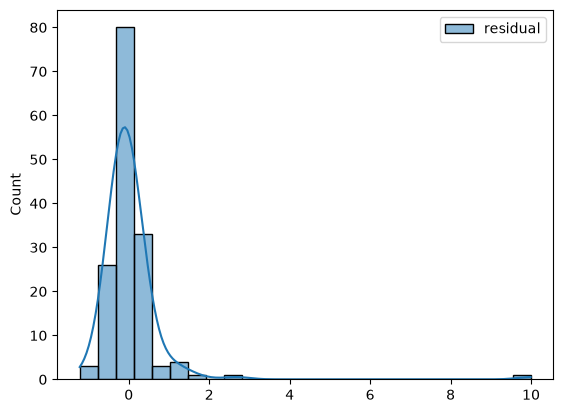

In [30]:
residual1 = df_statsmod['actual_price'] - df_statsmod['prediction_price']
sns.histplot(residual1, kde=True, label="residual")
plt.legend()
plt.show()

**Interpretasi:** Sebagian besar residual berkumpul di antara −1 dan 1 dengan puncak di sekitar 0. Tapi ada satu residual yang sangat ekstrem di sekitar +10 dan beberapa di kisaran +1,3 sampai +2,7, jadi distribusinya punya ekor panjang ke kanan. Kesimpulan visual ini kita pastikan dengan Shapiro-Wilk.

In [31]:
stat, p = shapiro(residual1)
print('Statistics=%.3f, p=%.3f' % (stat, p))
alpha = 0.05
if p > alpha:
    print('Gagal Tolak H0, residual berdistribusi normal')
else:
    print('Tolak H0, residual tidak berdistribusi normal')

Statistics=0.404, p=0.000
Tolak H0, residual tidak berdistribusi normal


**Interpretasi:** Statistik W = 0,404 dengan p < 0,05 (sekitar 2,6 × 10⁻²²), jadi H0 ditolak dan residual tidak berdistribusi normal. Penyebab utamanya outlier harga, terutama satu saham dengan residual sekitar +10 (dibahas di eksperimen outlier).

**Keputusan:** asumsi normalitas residual tidak terpenuhi. Konsekuensinya, hasil uji-T dan uji-F sebaiknya dibaca sebagai indikasi, bukan kebenaran mutlak.

In [32]:
df_statsmod["residual"] = residual1
df_statsmod.head()

,Earnings/Share,Dividend Yield,Price/Sales,actual_price,prediction_price,residual
90,0.029234,-1.224106,-0.942857,-0.297597,0.097954,-0.395551
97,-0.097512,-1.224106,-1.000429,-0.002291,0.022054,-0.024345
477,-0.171162,-0.786062,3.253896,0.108387,0.641211,-0.532824
340,1.313820,-0.411043,-0.479217,1.831279,0.681360,1.149919
395,-0.237960,-0.280665,0.728446,-0.093293,0.061123,-0.154416


**Interpretasi:** Sekarang ada kolom `residual` yang berisi selisih aktual dikurangi prediksi. Contohnya baris 340 punya residual +1,150, artinya harga aslinya lebih tinggi sekitar 1,15 SD (≈ 140 USD) dari prediksi model.

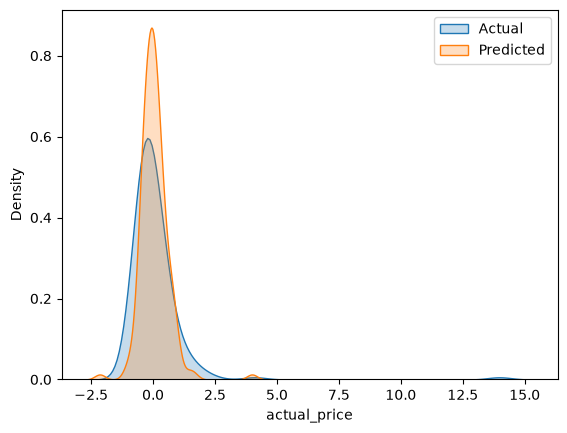

In [33]:
sns.kdeplot(df_statsmod['actual_price'], label="Actual", fill=True)
sns.kdeplot(df_statsmod['prediction_price'], label="Predicted", fill=True)
plt.legend()
plt.show()

**Interpretasi:** Kurva prediksi (oranye) lebih sempit dan lebih tinggi daripada kurva aktual (biru), sementara kurva aktual punya ekor panjang sampai sekitar 14 SD (saham PCLN). Artinya model cenderung menebak harga di sekitar rata-rata dan kurang bisa menangkap harga yang sangat tinggi. Ini menjelaskan kenapa R² model tidak tinggi.

## Uji autokorelasi

Kriteria Durbin-Watson: < 1,5 ada autokorelasi positif; 1,5–2,5 tidak ada autokorelasi; > 2,5 ada autokorelasi negatif.

In [34]:
durbin_watson(results.resid, axis=0)

np.float64(1.9811228548336572)

**Interpretasi:** Nilai Durbin-Watson = 1,981, berada di antara 1,5 dan 2,5. Jadi tidak ada autokorelasi.

**Keputusan:** asumsi terpenuhi. Tapi perlu dicatat, uji ini paling bermakna untuk data deret waktu. Data kita *cross-sectional* (satu baris satu perusahaan), dan urutan barisnya sudah diacak oleh `train_test_split`, jadi hasil ini sifatnya pelengkap saja.

## Uji homoskedastisitas

Homoskedastisitas artinya varians residual konstan. Model yang baik tidak menunjukkan pola tertentu di grafik residual terhadap nilai prediksi.

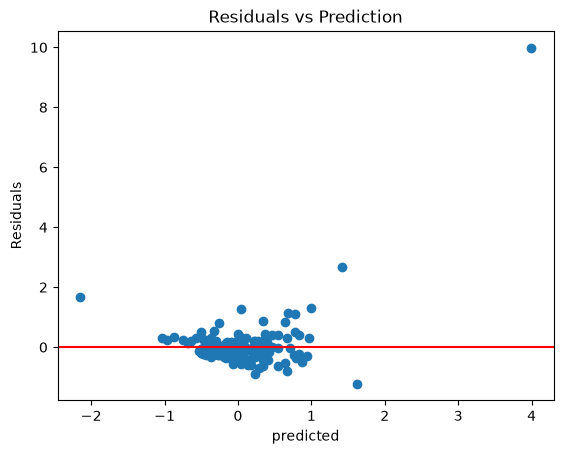

In [35]:
plt.scatter(df_statsmod['prediction_price'], df_statsmod["residual"])
plt.axhline(0, color='red')
plt.xlabel('predicted')
plt.ylabel('Residuals')
plt.title('Residuals vs Prediction')
plt.show()

**Interpretasi:** Sebagian besar titik berkumpul di sekitar garis 0 pada prediksi −1 sampai 1. Tapi sebarannya melebar ke arah prediksi yang lebih tinggi, dan ada satu titik yang sangat ekstrem (prediksi ≈ 4, residual ≈ +10) dari saham PCLN. Ada juga titik di prediksi ≈ −2,1 dengan residual positif (sekitar +1,7). Itu perusahaan dengan EPS sangat negatif yang harganya ternyata tidak serendah tebakan model, sesuai dengan pola "V" di uji linearitas. Pola melebar seperti ini adalah tanda heteroskedastisitas.

In [36]:
bp_lm, bp_lm_p, bp_f, bp_f_p = het_breuschpagan(results.resid, results.model.exog)
print("Breusch-Pagan LM :", bp_lm)
print("P-value          :", bp_lm_p)

if bp_lm_p < 0.05:
    print("Tolak H0, terdapat heteroskedastisitas")
else:
    print("Gagal Tolak H0, residual homoskedastis")

Breusch-Pagan LM : 8.556954568619712
P-value          : 0.03579996758967744
Tolak H0, terdapat heteroskedastisitas


**Interpretasi:** Sebagai pelengkap, uji Breusch-Pagan (H0: varians residual konstan) pada residual data latih menghasilkan LM ≈ 8,56 dengan p ≈ 0,036. Karena p < 0,05, H0 ditolak dan ada heteroskedastisitas.

**Keputusan:** asumsi homoskedastisitas tidak terpenuhi (tingkatnya ringan sampai sedang). Hasil ini sejalan dengan scatter plot yang sebarannya melebar.

## Evaluasi model

Evaluasi dilakukan di data uji. Karena datanya sudah distandardisasi, MSE, RMSE, dan MAE masih dalam satuan simpangan baku `Price`. Di bagian akhir kita ubah ke USD.

In [37]:
print('R-square :', metrics.r2_score(df_statsmod['actual_price'], df_statsmod['prediction_price']))

R-square : 0.49040893378503025


**Interpretasi:** R² data uji ≈ 0,490, malah lebih tinggi dari R² data latih (≈ 0,347). Ini bukan berarti model lebih jago di data baru. Penyebabnya pembagian datanya: data latih memuat AMZN, GOOGL, dan GOOG yang residualnya besar sekali (sekitar 5–10 SD) sehingga R² latih tertekan. Sementara itu, data uji memuat PCLN yang harganya ekstrem tapi masih ikut diprediksi tinggi oleh model, sehingga variasi total data uji ikut membesar. Ini dicek lagi di eksperimen outlier.

In [38]:
print('MSE :', metrics.mean_squared_error(df_statsmod['actual_price'], df_statsmod['prediction_price']))

MSE : 0.8661615291464149


**Interpretasi:** MSE = 0,866 (satuan SD kuadrat). Sebagai pembanding, kalau kita cuma menebak semua harga sama dengan rata-rata, MSE di data uji sekitar 1,70 (varians `Price` di data uji). Jadi model sudah mengurangi galat, tapi angka ini paling berguna kalau dibandingkan dengan model lain.

In [39]:
mae = metrics.mean_absolute_error(df_statsmod['actual_price'], df_statsmod['prediction_price'])
rmse = np.sqrt(metrics.mean_squared_error(df_statsmod['actual_price'], df_statsmod['prediction_price']))

print('MAE  :', mae)
print('RMSE :', rmse)

sd_price = scaler_y.scale_[0]
print('MAE  (USD):', mae * sd_price)
print('RMSE (USD):', rmse * sd_price)

MAE  : 0.3719731691612373
RMSE : 0.9306779943387589
MAE  (USD): 45.37148213171433
RMSE (USD): 113.5195855274635


**Interpretasi:**
- **MAE = 0,372 SD, sekitar 45 USD:** rata-rata tebakan model meleset sekitar 45 USD per saham.
- **RMSE = 0,931 SD, sekitar 114 USD:** RMSE jauh lebih besar dari MAE (sekitar 2,5 kali) karena galat besar dihukum lebih berat lewat pengkuadratan. Selisih sebesar ini menandakan ada beberapa galat yang sangat besar (outlier).

Kalau dibandingkan dengan harga rata-rata sekitar 104 USD (median sekitar 74 USD), galat sekitar 45–114 USD itu besar. Jadi model ini belum cocok untuk memprediksi harga saham secara presisi, tapi masih berguna untuk melihat arah dan kekuatan pengaruh tiap fitur.

---

# Uji hipotesis dan kesimpulan

## Uji parsial (uji-T)

H0: βj = 0 (fitur tidak berpengaruh) dan H1: βj ≠ 0, dengan α = 0,05.

In [40]:
t_test_const, t_test_X1, t_test_X2, t_test_X3 = results.tvalues
print("T-test score const          : ", t_test_const)
print("T-test score Earnings/Share : ", t_test_X1)
print("T-test score Dividend Yield : ", t_test_X2)
print("T-test score Price/Sales    : ", t_test_X3)

T-test score const          :  1.8051249091246231e-16
T-test score Earnings/Share :  11.972271586127922
T-test score Dividend Yield :  -4.676941677606618
T-test score Price/Sales    :  4.051477241338552


**Interpretasi:** Makin besar nilai |t|, makin kuat pengaruhnya. Urutannya `Earnings/Share` (t ≈ 11,97) ≫ `Dividend Yield` (t ≈ −4,68) > `Price/Sales` (t ≈ 4,05) ≫ const (t ≈ 0). Tanda negatif di `Dividend Yield` artinya arah pengaruhnya berlawanan.

In [41]:
p_value_const, p_value_X1, p_value_X2, p_value_X3 = results.pvalues
print("P-value const          : ", p_value_const)
print("P-value Earnings/Share : ", p_value_X1)
print("P-value Dividend Yield : ", p_value_X2)
print("P-value Price/Sales    : ", p_value_X3)

P-value const          :  0.9999999999999999
P-value Earnings/Share :  6.587286298007603e-28
P-value Dividend Yield :  4.169181374527409e-06
P-value Price/Sales    :  6.276716693431039e-05


**Interpretasi:** Ketiga fitur punya p < 0,05 (`Earnings/Share` ≈ 6,6 × 10⁻²⁸; `Dividend Yield` ≈ 4,2 × 10⁻⁶; `Price/Sales` ≈ 6,3 × 10⁻⁵), jadi H0 ditolak dan ketiganya berpengaruh signifikan terhadap harga saham. Const punya p ≈ 1 sehingga tidak signifikan, tapi ini wajar untuk data yang distandardisasi dan bukan temuan penting.

## Uji simultan (uji-F)

H0: β1 = β2 = β3 = 0 (semua fitur bersama-sama tidak berpengaruh).

In [42]:
f_value = results.fvalue
print("f-test score : ", f_value)

p_value = results.f_pvalue
print("P-value : ", p_value)

if p_value < 0.05:
    print("Tolak H0")
else:
    print("Terima H0")

f-test score :  61.75066642094763
P-value :  4.7636299068681997e-32
Tolak H0


**Interpretasi:** F ≈ 61,75 dengan p ≈ 4,76 × 10⁻³² < 0,05, jadi H0 ditolak dan model layak dipakai secara simultan. Tapi "layak" di sini cuma berarti model lebih baik daripada tidak memakai prediktor sama sekali, bukan berarti prediksinya akurat. Keakuratan tetap dilihat dari metrik evaluasi (R², MSE, RMSE, MAE).

## Eksperimen tambahan: pengaruh outlier

Kita cari baris dengan residual mutlak terbesar di data uji, lalu hitung ulang R² dan MSE tanpa baris tersebut.

In [43]:
idx_terburuk = df_statsmod["residual"].abs().idxmax()
print(df.loc[idx_terburuk, ["Symbol", "Name", "Price"]])
print()
print(df_statsmod.loc[idx_terburuk])

mask = df_statsmod.index != idx_terburuk
print()
print("R-square tanpa outlier :", metrics.r2_score(df_statsmod.loc[mask, "actual_price"], df_statsmod.loc[mask, "prediction_price"]))
print("MSE tanpa outlier      :", metrics.mean_squared_error(df_statsmod.loc[mask, "actual_price"], df_statsmod.loc[mask, "prediction_price"]))

Symbol                 PCLN
Name      Priceline.com Inc
Price               1806.06
Name: 372, dtype: object

Earnings/Share       6.655988
Dividend Yield      -1.224106
Price/Sales          1.648432
actual_price        13.981705
prediction_price     3.992820
residual             9.988885
Name: 372, dtype: float64

R-square tanpa outlier : 0.5020013209308919
MSE tanpa outlier      : 0.2111173760935583


**Interpretasi:** Residual terbesar dimiliki Priceline (PCLN, baris 372) dengan harga asli 1.806,06 USD, atau sekitar 13,98 SD di atas rata-rata. Model memprediksi 3,99 SD (sekitar 588 USD), jadi residualnya ≈ +9,99 SD. EPS-nya memang sangat tinggi (sekitar 6,7 SD), tapi harganya jauh lebih tinggi lagi dari yang bisa dijelaskan model linear.

Setelah satu baris ini dikeluarkan, MSE turun drastis dari 0,866 menjadi 0,211 (turun sekitar 76%), sedangkan R² hanya naik sedikit dari 0,490 menjadi 0,502. R² tidak banyak berubah karena saat PCLN dibuang, variasi total data uji juga ikut mengecil.

Pelajarannya: satu saham saja bisa mendominasi galat model. Tapi menghapus data tidak boleh sembarangan. PCLN adalah data asli yang valid, jadi lebih baik pakai pendekatan seperti transformasi log atau regresi yang lebih *robust* daripada langsung membuangnya.

## Ringkasan seluruh uji

| Pengujian | Hasil | Keputusan |
|---|---|---|
| Normalitas variabel (Shapiro-Wilk) | p < 0,05 untuk keempat variabel | Tidak normal |
| Linearitas | Jelas di EPS positif, pola "V" di EPS negatif; lemah tapi lurus di Dividend Yield dan Price/Sales | Terpenuhi sebagian |
| Multikolinearitas | \|r\| antar-X ≤ 0,08; VIF ≈ 1,01; Cond. No. 1,07 | Terpenuhi |
| Normalitas residual | Shapiro-Wilk W = 0,404, p < 0,05 | Tidak terpenuhi |
| Autokorelasi | Durbin-Watson = 1,981 | Terpenuhi (pelengkap, data cross-sectional) |
| Homoskedastisitas | Sebaran melebar; Breusch-Pagan p ≈ 0,036 | Tidak terpenuhi (ringan–sedang) |
| Uji-T | p < 0,05 untuk ketiga fitur | Semua berpengaruh signifikan |
| Uji-F | F ≈ 61,75; p ≈ 4,76 × 10⁻³² | Model layak |
| R² (latih / uji) | 0,347 / 0,490 (0,502 tanpa PCLN) | Daya jelaskan sedang |
| MSE / RMSE / MAE (uji) | 0,866 / 0,931 / 0,372 SD (RMSE ≈ 114 USD, MAE ≈ 45 USD) | Galat cukup besar |

## Menjawab pertanyaan studi kasus

**1. Seberapa besar pengaruh variabel independen terhadap harga saham?**
Ketiga fitur signifikan secara statistik. Pengaruh terbesar dimiliki `Earnings/Share` (koefisien standar 0,519, atau sekitar +63 USD per kenaikan 1 SD EPS). Setelah itu `Dividend Yield` (−0,203, sekitar −25 USD per 1 SD) dan `Price/Sales` (0,175, sekitar +21 USD per 1 SD). Jadi laba per saham adalah penentu harga yang paling dominan di antara ketiganya.

**2. Bagaimana kualitas prediksinya?**
Model menjelaskan sekitar 35% variasi harga di data latih dan sekitar 49% di data uji. Angka R² uji yang lebih tinggi ini lebih banyak dipengaruhi pembagian outlier daripada kehebatan model. Rata-rata galatnya sekitar 45 USD (MAE) dan RMSE sekitar 114 USD, cukup besar dibanding harga median sekitar 74 USD. Selain itu asumsi normalitas residual dan homoskedastisitas tidak terpenuhi. Jadi model ini cukup untuk melihat arah dan kekuatan pengaruh, tapi belum cukup untuk memprediksi harga saham secara akurat.

**3. Langkah peningkatan apa yang bisa dilakukan?**
- Transformasi logaritma pada `Price` (dan `Price/Sales`) supaya distribusinya tidak terlalu miring dan pengaruh outlier berkurang.
- Menangani pola "V" pada `Earnings/Share`, misalnya dengan menambah variabel dummy untuk perusahaan yang rugi (EPS < 0).
- Menambahkan variabel `Sector` sebagai dummy (one-hot encoding), karena harga saham tiap sektor bisa berbeda karakternya.
- Memakai regresi yang lebih *robust* terhadap outlier, atau *robust standard errors* untuk mengatasi heteroskedastisitas.

---

# Tugas Diskusi (6.10.2)

**1. Kelebihan dan kekurangan MAE, MSE, RMSE, dan R²**

| Metrik | Kelebihan | Kekurangan |
|---|---|---|
| MAE | Gampang dipahami, satuannya sama dengan data asli, tidak terlalu terpengaruh outlier | Tidak menghukum galat besar secara khusus, dan secara matematis kurang praktis untuk optimasi (tidak bisa diturunkan di titik 0) |
| MSE | Menghukum galat besar lebih berat, mudah diturunkan, dan jadi dasar metode OLS | Satuannya kuadrat sehingga susah ditafsirkan, dan sangat sensitif terhadap outlier |
| RMSE | Satuannya kembali sama dengan data asli dan tetap menghukum galat besar | Masih sensitif terhadap outlier, dan susah dibandingkan antar-dataset yang skalanya berbeda |
| R² | Tanpa satuan, mudah dibandingkan, dan langsung menunjukkan proporsi variasi yang dijelaskan | Selalu naik kalau variabel ditambah (perlu Adj. R²), tidak menunjukkan besar galat, bisa negatif di data uji, dan R² tinggi belum tentu asumsinya terpenuhi |

**2. Apakah keempat parameter harus dipakai sekaligus?**
Tidak wajib, tapi sebaiknya dipakai kombinasi. R² menjawab "seberapa banyak variasi yang dijelaskan", sedangkan MAE/RMSE menjawab "seberapa besar melesetnya dalam satuan asli". Membandingkan RMSE dengan MAE juga berguna untuk mendeteksi outlier. Di praktikum ini RMSE sekitar 2,5 kali MAE, dan itu langsung menunjukkan ada galat ekstrem (PCLN). MSE dan RMSE sebenarnya membawa informasi yang sama (RMSE = √MSE), jadi untuk laporan cukup salah satu, biasanya RMSE karena satuannya lebih mudah dibaca.

**3. Kenapa R² data uji (0,29) lebih rendah dari data latih (0,44) di praktikum modul? Apa peran outlier?**
Di modul, data uji memuat satu rumah dengan luas basement sangat ekstrem (baris 279, sekitar 6.110 sq ft). Model memprediksi harganya sangat tinggi (+8,21 SD), padahal harga aslinya biasa saja, sehingga residualnya sekitar −8,48 SD. Satu galat sebesar ini membuat MSE uji melonjak dan R² uji turun. Setelah baris itu dikeluarkan, R² uji naik menjadi 0,439, hampir sama dengan R² latih. Jadi selisih R² latih–uji di modul hampir seluruhnya disebabkan satu outlier.

Di dataset saham kita kejadiannya justru terbalik (R² uji > R² latih), tapi penyebabnya sama-sama outlier: saham-saham ekstrem (AMZN, GOOGL, GOOG) kebetulan masuk data latih. Ini menunjukkan bahwa R² sangat sensitif terhadap ke mana outlier jatuh saat data dibagi.

**4. Kenapa scaler sebaiknya di-fit hanya pada data latih?**
Karena data uji harus diperlakukan seperti data baru yang belum pernah dilihat. Kalau scaler di-fit di seluruh data, rata-rata dan simpangan baku data uji ikut terpakai saat melatih model. Itu namanya *data leakage*: informasi dari data uji bocor ke proses training, sehingga hasil evaluasi bisa terlihat lebih bagus dari kenyataannya. Cara yang benar adalah split dulu, `fit` scaler di data latih, lalu `transform` data uji pakai parameter yang sama. Cara inilah yang dipakai di notebook ini.